In [ ]:
#!/usr/bin/env python
# coding: utf-8

# CS 763 - Lab 8 (GANs) Part-A

from tqdm import tqdm
import time
import sys
import os
import PIL
from torch.nn import functional as F
from torch import nn, optim
from torchvision import transforms, models, datasets
import matplotlib.pyplot as plt
import torchvision
import random
import torch
import numpy as np

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd drive/MyDrive/180050085_180050090_180070060_lab08/


/content/drive/.shortcut-targets-by-id/1WYdpV9Sm_9Iz19DHzAyuQ8AbX2eHTKQg/180050085_180050090_180070060_lab08


In [ ]:
# Check for GPU specs
get_ipython().system('nvidia-smi')

# device set to cuda if GPU available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Function to fix the seed for randomisation


def fix_seed(seed=0):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # if you are using multi-GPU.
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


fix_seed(763)

Sat Apr 17 11:18:29 2021       
+-----------------------------------------------------------------------------+
| NVIDIA-SMI 460.67       Driver Version: 460.32.03    CUDA Version: 11.2     |
|-------------------------------+----------------------+----------------------+
| GPU  Name        Persistence-M| Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp  Perf  Pwr:Usage/Cap|         Memory-Usage | GPU-Util  Compute M. |
|                               |                      |               MIG M. |
|===============================+======================+======================|
|   0  Tesla T4            Off  | 00000000:00:04.0 Off |                    0 |
| N/A   47C    P8    10W /  70W |      0MiB / 15109MiB |      0%      Default |
|                               |                      |                  N/A |
+-------------------------------+----------------------+----------------------+
                                                                               
+-------

Lenth of Trainset = 60000
Lenth of Testset = 10000
Dimensions of each image = (28,28)


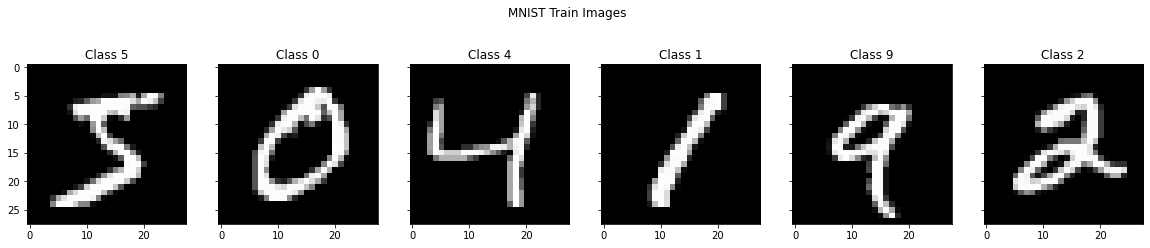

In [ ]:
# We will use the MNIST dataset for Part A of the lab.

# define transformations to be applied on the input images
# Input images from the dataset are PIL objects, hence we first convert them to Tensors, then we normalise them
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5), std=(0.5))])

trainset = torchvision.datasets.MNIST(
    './data', download=True, train=True, transform=transform)
testset = torchvision.datasets.MNIST(
    './data', download=True, train=False, transform=transform)

# dataloaders
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=128, num_workers=2, shuffle=True)
testloader = torch.utils.data.DataLoader(
    trainset, batch_size=128, num_workers=2)

# Visualising the dataset
print('Lenth of Trainset = {}'.format(len(trainset)))
print('Lenth of Testset = {}'.format(len(testset)))
print('Dimensions of each image = ({},{})'.format(
    trainset[0][0].shape[1], trainset[0][0].shape[2]))
fig, axs = plt.subplots(1, 6, sharey=True, figsize=(20, 4))
for i in range(6):
    axs[i].imshow(trainset[i][0].squeeze(), cmap='gray')
    axs[i].set_title('Class {}'.format(trainset[i][1]))
plt.suptitle('MNIST Train Images')
plt.show()

In [ ]:
# Generator and Discriminator Architecures
# The generator takes a noise vector of size (B,100), where B is the batch size and produces a 28x28 image
class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        ## TODO ##
        # Filters [1024, 512, 256]
        # Input_dim = 100
        # Output_dim = 1x28x28

        # Z latent vector 100
        self.inp = nn.Sequential(
            nn.Linear(100,256*7*7,bias=False),
            nn.BatchNorm1d(256*7*7),
            nn.LeakyReLU(0.3,inplace=True))
         
        self.cnn = nn.Sequential(
            # State (256x7x7)    
            nn.ConvTranspose2d(in_channels=256, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(num_features=128),
            nn.LeakyReLU(0.3,inplace=True),

            # State (128x7x7)
            nn.ConvTranspose2d(in_channels=128, out_channels=64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(num_features=64),
            nn.LeakyReLU(0.3,inplace=True),

            # State (64x14x14)
            nn.ConvTranspose2d(in_channels=64, out_channels=1, kernel_size=4, stride=2, padding=1))
            # output of cnn --> Image (1x28x28)

        self.output = nn.Tanh()

        ## TODO ##

    # forward pass
    def forward(self, x):
        ## TODO ##
        x = self.inp(x)
        x = x.view(x.shape[0],256,7,7)
        x = self.cnn(x)
        return self.output(x)
        ## TODO ##
        
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        ## TODO ##
        # Input_dim = 1x28x28
        # Output_dim = 1
        self.cnn = nn.Sequential(
            # State (1x28x28)
            nn.Conv2d(in_channels=1, out_channels=64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.3, inplace=True),
            nn.Dropout(0.3),

            # State (64x14x14)
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.3, inplace=True),
            nn.Dropout(0.3))
            # output of cnn --> (128x7x7)
            
        self.output = nn.Sequential(
              nn.Linear(128*7*7,1),
              nn.Sigmoid())
        ## TODO ##

    # forward pass
    def forward(self, x):
        ## TODO ##
        x = self.cnn(x)
        x = x.view(x.shape[0],-1)
        # print(x.shape)
        return self.output(x)
        ## TODO ##


        # Create the models
G = Generator().to(device)
D = Discriminator().to(device)

In [ ]:
# Create a BCELoss object
## TODO ##
criterion = nn.BCELoss().to(device)
## TODO ##

# Define two separate optimizers for generator and discriminator
## TODO ##
optimizer_g = torch.optim.Adam(G.parameters(), lr=0.0002)
# scheduler_g = optim.lr_scheduler.StepLR(optimizer_g, 10, 0.5) 
optimizer_d = torch.optim.Adam(D.parameters(), lr=0.0002)
# scheduler_d = optim.lr_scheduler.StepLR(optimizer_d, 10, 0.5)
## TODO ##

In [ ]:
# Train Function
# returns the total loss for the epoch
def train(epoch):
    loss_acc_g = 0
    loss_acc_d = 0
    loss_acc = 0

    for i, (images, _) in tqdm(enumerate(trainloader), desc="Training for epoch {}".format(epoch), total=len(trainloader)):
        optimizer_d.zero_grad()
        # Discriminator training on real images
        ## TODO ##
        batch_size = images.shape[0]
        images = images.to(device)
        real_labels = torch.ones((batch_size,1)).to(device)
        fake_labels = torch.zeros((batch_size,1)).to(device)
        prediction_on_real = D(images)
        loss_real = criterion(prediction_on_real, real_labels)
        ## TODO ##
        # Discriminator training on fake images
        ## TODO ##
        z = torch.rand((batch_size, 100)).to(device)
        fake_samples = G(z)
        prediction_on_fake = D(fake_samples.detach())  # don't forget to use detach() here
        loss_fake = criterion(prediction_on_fake, fake_labels)
        ## TODO ##
        loss_d = loss_real + loss_fake
        loss_d.backward()
        optimizer_d.step()

        # Generator training
        optimizer_g.zero_grad()
        ## TODO ##
        z = torch.randn((batch_size,100)).to(device)
        fake_samples = G(z)
        prediction_on_fake = D(fake_samples)
        loss_g = criterion(prediction_on_fake, real_labels)
        ## TODO ##
        loss_g.backward()
        optimizer_g.step()

        loss_acc += (loss_g + loss_d).item()
        loss_acc_g += loss_g.item()
        loss_acc_d += loss_d.item()

    return loss_acc/i, loss_acc_g/i, loss_acc_d/i


In [ ]:
# Functions to save and load checkpoints

# Enter the path on your shared drive where the checkpoint is to be saved
## TODO ##
path_to_checkpoint = './results/vanilla/'
## TODO ##


def save_checkpoint(e):
    if not os.path.isdir(path_to_checkpoint):
        os.mkdir(path_to_checkpoint)
    torch.save({'e': e, 'gen': G.state_dict(), 'disc': D.state_dict(), 'optim_d': optimizer_d.state_dict(
    ), 'optim_g': optimizer_g.state_dict()}, os.path.join(path_to_checkpoint, 'checkpoint_vanilla.pth'))


def load_checkpoint():
    if not os.path.isfile(os.path.join(path_to_checkpoint, 'checkpoint_vanilla.pth')):
        return -1
    dic = torch.load(os.path.join(
        path_to_checkpoint, 'checkpoint_vanilla.pth'))
    G.load_state_dict(dic['gen'])
    D.load_state_dict(dic['disc'])
    optimizer_d.load_state_dict(dic['optim_d'])
    optimizer_g.load_state_dict(dic['optim_g'])
    return dic['e']

In [ ]:
# The generate functions are defined here
def generate(n):
    pass
    ## TODO ##
    z = torch.randn((n,100))
    z = z.to(device)
    output = G(z).to("cpu").detach()
    return output
    ## TODO ##


In [ ]:
## TODO ##
NUM_EPOCHS = 50
## TODO ##
losses_g = []
losses_d = []

In [ ]:
# Resume training
offset = load_checkpoint()
# offset = -1
if os.path.exists('images/vanilla'):
    if offset == -1:
        os.system('rm -rf images/vanilla')
        os.mkdir('images/vanilla')
else:
    os.mkdir('images/vanilla')


Training for epoch 0: 100%|██████████| 469/469 [00:12<00:00, 38.12it/s]


loss_g = 4.978561783702965, loss_d = 0.07761911053855258



Training for epoch 1: 100%|██████████| 469/469 [00:12<00:00, 38.18it/s]


loss_g = 4.48629789525627, loss_d = 0.18600099033110926



Training for epoch 2: 100%|██████████| 469/469 [00:12<00:00, 37.89it/s]


loss_g = 3.6183188975366773, loss_d = 0.3338793896170508



... (90 outputs left out)

Training for epoch 48: 100%|██████████| 469/469 [00:12<00:00, 38.40it/s]


loss_g = 1.4109415076991432, loss_d = 1.0701040084290707



Training for epoch 49: 100%|██████████| 469/469 [00:12<00:00, 38.02it/s]


loss_g = 1.3881792494883904, loss_d = 1.0677714327461698



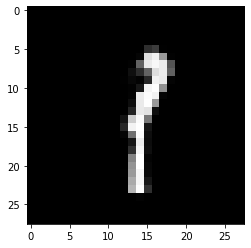

In [ ]:
for e in range(NUM_EPOCHS):
    if e <= offset:
        continue
    loss, loss_g, loss_d = train(e)
    # scheduler_g.step();
    # scheduler_d.step();
    losses_g.append(loss_g)
    losses_d.append(loss_d)
    G.eval()
    g_output = generate(1)[0]
    G.train()
    plt.imshow(g_output.reshape(28, 28), cmap='gray')
    plt.savefig('./images/vanilla/{}.png'.format(e))
    print('loss_g = {}, loss_d = {}\n'.format(loss_g, loss_d))
    save_checkpoint(e)

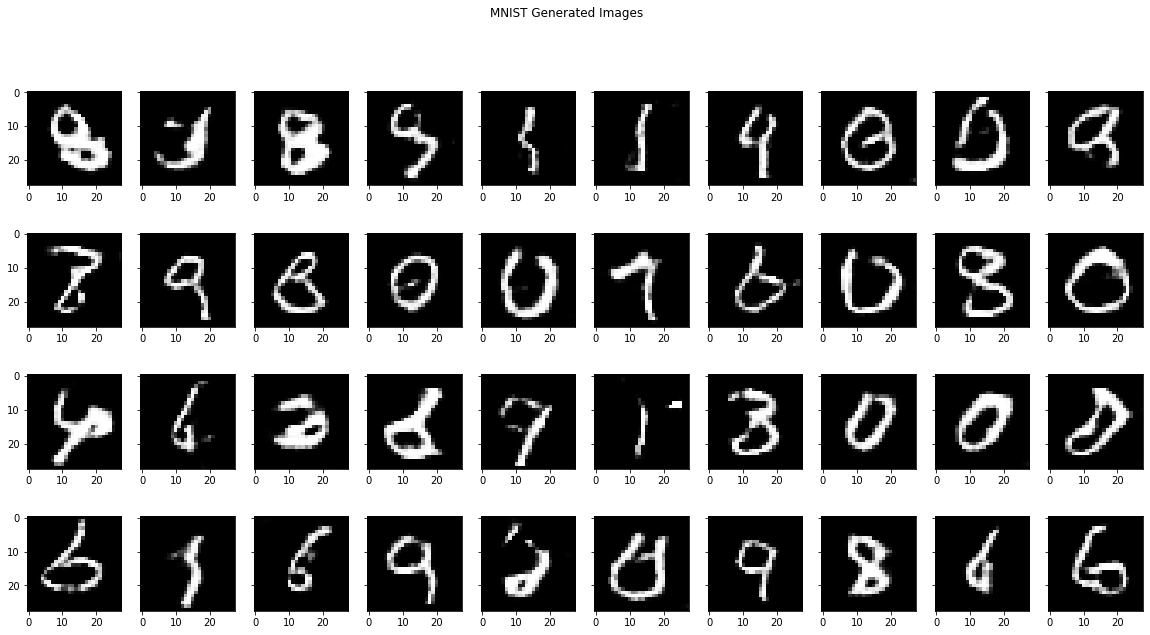

In [ ]:
# Test script
load_checkpoint()
with torch.no_grad():
    G.eval()
    fake_images = generate(40)
    fig, axs = plt.subplots(4, 10, sharey=True, figsize=(20, 10))
    for i in range(40):
        axs[i//10, i % 10].imshow(fake_images[i].reshape(28, 28), cmap='gray')
    plt.suptitle('MNIST Generated Images')
    plt.show()